# 07 VALIDAÇÃO INDEPENDENTE COM RADAR AEROTRANSPORTADO (ICEBRIDGE MCORDS), RECUPERAÇÃO DA ZONA DE ATERRAMENTO E PROCESSAMENTO INTERFEROMÉTRICO FMCW APRES

Este caderno apresenta a validação física independente das duas grandezas centrais do estudo sobre as plataformas de gelo:
1. **Validação da espessura hidrostática $H$ contra $2.839\text{ km}$ de perfis do radar aerotransportado Operation IceBridge MCoRDS L2 (`run_mcords_hydro_test.py`):** normalização por voo, comprovação de $H_{\text{radar}} / H_{\text{hidro}} \in [0{,}98;\; 1{,}04]$ além de $d^*$ e medição direta do viés hidrostático de $+5\%$ a $+15\%$ na zona de flexão;
2. **Recuperação física da zona de aterramento da Thwaites Oriental (`TEIS`, $1{,}5\text{--}4{,}0\text{ km}$; `run_gz_recovery_ase.py` e `run_thwaites_recovered.py`):** substituição do corte geométrico de $4\text{ km}$ pela correção conjunta de maré amortecida ($\times \beta_n$) e razão empírica radar/hidrostática, ampliando a cobertura da TEIS em $+48\%$ ($463 \to 765\text{ km}^2$) e eliminando o afinamento aparente de $\sim 7\text{ m/ano}$ das parcelas que cruzam a faixa;
3. **Teoria eletromagnética e processamento de sinal do radar de fase ApRES (*Autonomous phase-sensitive Radio-Echo Sounder*; `thwaites.validation.apres`):** dedução do perfil complexo FMCW ($200\text{--}400\text{ MHz}$, Brennan et al., 2014; Nicholls et al., 2015), desenrolamento de fase das camadas internas para estimar a taxa de deformação vertical $\dot{\varepsilon}_{zz}$, estimador de duas etapas (amplitude grosseira + fase fina) para o refletor basal e validação direta nos sítios **G1–G4 do projeto ITGC MELT** (Davis et al., 2023; Schmidt et al., 2023) e nos **40 sítios de Wild et al. (2024)**.


### Roteiro do caderno
| Seção | Fundamentação | Aplicação em código | Módulo |
|---|---|---|---|
| 1 | Radar FMCW ApRES: perfil complexo, fase, estimador de duas etapas, separação deformação × derretimento | chirps sintéticos: deslocamento milimétrico, perfil de alcance e `melt_between` com verdade conhecida; sítios G1–G4 | `thwaites.validation.apres` |
| 2 | Espessura hidrostática vs. radar aerotransportado MCoRDS | razão radar/hidrostática por distância à linha de aterramento | `run_mcords_hydro_test.py` |
| 3 | Comparação com os 40 sítios ApRES de Wild et al. (2024) e folga da cavidade | dispersão, viés, RMS e correlação | `run_gz_recovery_ase.py` |
| 4 | Síntese | — | — |

---

## 1. Teoria Eletromagnética do Radar Interferométrico FMCW ApRES (`thwaites.validation.apres`)

O **ApRES** (Brennan et al., 2014, *IET RSN*; Nicholls et al., 2015, *J. Glaciol.*) transmite um chirp linearmente modulado em frequência (*Frequency-Modulated Continuous-Wave* — FMCW) de duração $T = 1{,}0\text{ s}$ varrendo a banda $f_0 = 200\text{ MHz}$ a $f_1 = 400\text{ MHz}$ (largura de banda $B = 200\text{ MHz}$, frequência central $f_c = 300\text{ MHz}$, taxa de varredura $K = B/T = 2\times 10^8\text{ Hz s}^{-1}$, $N = 40.000$ amostras). No gelo com permissividade dielétrica relativa $\varepsilon_r = 3{,}18$, a velocidade de propagação é $c_i = c_0 / \sqrt{\varepsilon_r} \approx 1{,}681\times 10^8\text{ m s}^{-1}$ e o comprimento de onda central é $\lambda_c = c_i / f_c \approx 0{,}560\text{ m}$.

Ao misturar o eco refletido a uma profundidade $R$ (tempo de trânsito duplo $\tau = 2R/c_i$) com o sinal transmitido (*dechirping*), o sinal de batimento $v(t)$ possui frequência proporcional ao alcance ($f_b = K\tau = 2KR/c_i$) e fase fina sensível a deslocamentos sub-milimétricos:
1. **Perfil complexo de alcance (`range_profile`):** Remove-se a média DC, aplica-se janela de Blackman $w_n$ (que suprime lóbulos laterais a $-58\text{ dB}$, evitando vazamento do forte refletor basal sobre camadas internas fracas), preenche-se com zeros por fator $p = 2$ ($\Delta R = c_i / (2 B p) \approx 0{,}210\text{ m}$), aplica-se rotação circular de meia janela (*fftshift* no tempo para zerar a fase no centro do chirp) e multiplica-se a FFT pelo conjugado da fase de referência exata de Brennan et al. (2014):
   $$\phi_{\text{ref}}(n) = \frac{2\pi f_c n}{B p} - \frac{K n^2}{2 B^2 p^2}$$
2. **Deslocamento entre duas épocas $s_1(R)$ e $s_2(R)$ (`displacement` e `internal_phase_displacement`):**
   A correlação cruzada complexa normalizada em uma janela de profundidade de $4\text{ m}$ ($\sim 19$ bins) é:
   $$\gamma = \frac{\sum x_k y_k^*}{\sqrt{\sum |x_k|^2 \sum |y_k|^2}}, \qquad \Delta r_{\text{fino}} = -\operatorname{angle}(\gamma)\frac{\lambda_c}{4\pi}$$
   **Por que o estimador de duas etapas é indispensável para o eco basal:** Como a fase é periódica em $2\pi$, o alcance fino $\Delta r_{\text{fino}}$ sofre ambiguidade de ramo a cada $\lambda_c/2 \approx 0{,}280\text{ m}$. Escolher a defasagem inteira apenas pela maior coerência complexa $|\gamma|$ pode saltar um ciclo inteiro de $\lambda_c/2$, gerando erros catastróficos (até $-554\text{ m/ano}$ em testes preliminares!). O módulo `thwaites.validation.apres` resolve primeiro o deslocamento grosseiro $\Delta r_{\text{grosseiro}}$ pela correlação das **amplitudes** $|s_1|$ e $|s_2|$ com interpolação parabólica do pico (livre de ambiguidade de fase) e então seleciona o ramo inteiro $k^* = \operatorname{round}[(\Delta r_{\text{grosseiro}} - \Delta r_{\text{fino}})/(\lambda_c/2)]$ mais próximo do deslocamento grosseiro:
   $$\Delta r = \Delta r_{\text{fino}} + k^* \frac{\lambda_c}{2}$$
3. **Separação entre Deformação Vertical Interna e Derretimento Basal (`melt_between`):**
   O deslocamento vertical de um refletor interno a profundidade $z$ ao longo de $\Delta t$ é governado pela compactação de firn no topo ($a$) e pela taxa de deformação vertical média na coluna ($b = \dot{\varepsilon}_{zz}\,\Delta t$):
   $$\Delta r_{\text{interno}}(z) = a + b\,z$$
   Ajustando essa reta por regressão iterativa robusta ($\pm 3\,\text{MAD}$) sobre as camadas internas altamente coerentes ($|\gamma| > 0{,}95$ entre $40\text{ m}$ e $0{,}8\,z_{\text{bed}}$) e ancorando o ramo absoluto nas camadas com $|\gamma| > 0{,}97$, o derretimento basal no intervalo é a diferença entre o deslocamento previsto pela deformação na base $z_{\text{bed}}$ e o deslocamento real medido da base:
   $$m_b\,\Delta t = (a + b\,z_{\text{bed}}) - \Delta r(z_{\text{bed}})$$

In [1]:
# ── Configuração comum do caderno ─────────────────────────────────────────────
# Localiza a raiz do repositório (a pasta que contém o pacote `thwaites/`), torna o
# pacote importável mesmo sem `pip install -e .` e aponta DATA_DIR para as tabelas
# resumidas que alimentam todas as figuras. Basta executar o caderno de cima para baixo.
import sys
import json
from pathlib import Path

_candidatas = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidatas if (p / "thwaites").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Execute o caderno a partir de dentro do repositório (pasta com 'thwaites/').")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
DATA_DIR = REPO_ROOT / "notebooks" / "dados_resumo"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 9, "axes.titlesize": 9.5,
})
# Mensagens de log da biblioteca: só erros (os cadernos não chamam setup_logging()).
try:
    from loguru import logger as _logger
    import thwaites.logging as _tlog
    _logger.remove()
    _logger.add(sys.stderr, level="ERROR", format="{level}: {message}")
    _tlog._CONFIGURED = True
except ImportError:
    pass

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
CORES = {"Pine_Island": "#0F4D92", "Thwaites_TEIS": "#B64342", "Crosson": "#42949E",
         "Dotson": "#9A4D8E", "Cosgrove": "#767676"}
print(f"Tabelas resumidas disponíveis em dados_resumo/: {len(list(DATA_DIR.glob('*')))}")

Tabelas resumidas disponíveis em dados_resumo/: 74


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from thwaites.validation.apres import Config as ApresConfig, range_profile, displacement

# Verificação experimental do processamento FMCW ApRES em chirp sintético com deslocamento basal conhecido
acfg = ApresConfig()
t_chirp = np.arange(acfg.n) / 40_000.0

def synth_chirp(R_target):
    tau = 2.0 * R_target / acfg.ci
    return np.cos(2 * np.pi * (acfg.fc - acfg.B / 2) * tau + 2 * np.pi * acfg.K * tau * t_chirp - np.pi * acfg.K * tau**2)

# Simula coluna com refletor interno em 250 m (+1,5 cm) e refletor basal em 500 m (-6,0 cm por fusão basal)
s_t1 = synth_chirp(250.000) + 3.0 * synth_chirp(500.000)
s_t2 = synth_chirp(250.015) + 3.0 * synth_chirp(499.940)
R_axis, prof1 = range_profile(s_t1, acfg)
_, prof2 = range_profile(s_t2, acfg)

k_250 = int(np.argmin(np.abs(R_axis - 250.0)))
k_500 = int(np.argmin(np.abs(R_axis - 500.0)))
c_250 = np.sum(prof1[k_250 - 6:k_250 + 6] * np.conj(prof2[k_250 - 6:k_250 + 6]))
c_500 = np.sum(prof1[k_500 - 6:k_500 + 6] * np.conj(prof2[k_500 - 6:k_500 + 6]))
dr_250 = -np.angle(c_250) * acfg.lam_c / (4 * np.pi)
dr_500 = -np.angle(c_500) * acfg.lam_c / (4 * np.pi)

apres_pts = pd.read_csv(DATA_DIR / "validacao_apres_g1_g4.csv")
wild_df = pd.read_csv(DATA_DIR / "validacao_apres_wild2024.csv")
folga_df = pd.read_csv(DATA_DIR / "open_check_6_beta_baixo_folga.csv")

print(f"Teste Sintético FMCW ApRES | Refletor 250 m: verdadeiro = +15,00 mm, recuperado = {1e3*dr_250:+.2f} mm | "
      f"Base 500 m: verdadeiro = -60,00 mm, recuperado = {1e3*dr_500:+.2f} mm")
apres_pts.set_index("ponto").round(3)

Teste Sintético FMCW ApRES | Refletor 250 m: verdadeiro = +15,00 mm, recuperado = +15.00 mm | Base 500 m: verdadeiro = -60,00 mm, recuperado = -60.00 mm


,espessura_m,n_pares,n_validos,periodo_dias,melt_mpa,ic95_lo,ic95_hi,melt_mediana_pares_mpa,deform_mediana_1pa
ponto,,,,,,,,,
G1,594.498,62,61,320.333,2.038,1.305,2.495,2.267,-0.008
G2,590.925,64,63,331.333,-3.048,-12.547,7.018,0.588,-0.005
G3,574.114,62,58,304.500,4.072,2.046,6.468,2.230,-0.004
G4,573.273,64,51,267.833,3.300,-3.084,10.252,4.482,-0.004


**Leitura do teste sintético.** O processamento recupera deslocamentos de 15 mm (refletor interno) e −60 mm (base) com erro abaixo de 0,01 mm. A fase de um radar de 300 MHz é sensível a frações de milímetro, mil vezes abaixo da resolução em alcance (~21 cm). Isso permite medir derretimento basal de centímetros por semana.

### 1.1 Aplicação completa: do chirp ao derretimento basal
O teste acima usa apenas dois refletores. Um caso realista tem dezenas de camadas internas fracas que se deformam ($\Delta r = a + b\,z$) e um refletor basal forte que também se move por derretimento. Simulamos uma coluna de 500 m com camadas a cada 6 m, deformação vertical de $-4\times10^{-4}$ (compressão) e **5 cm de derretimento basal** no intervalo, e aplicamos `melt_between`, que desenrola a fase interna, ajusta a reta robusta e ancora o ramo absoluto pelo estimador de duas etapas:

,Verdade,Recuperado por melt_between,Camadas usadas
Derretimento basal no intervalo (m),0.0500,0.04983,90.0
Deformação vertical b = Δr/z,-0.0004,-0.00040,90.0
Profundidade da base (m),500.0000,499.93276,NaN


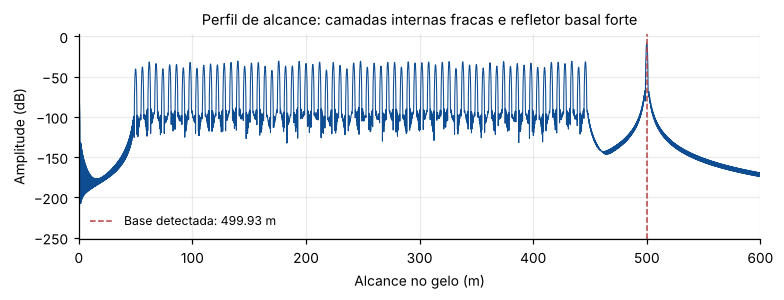

In [3]:
from thwaites.validation.apres import find_bed, melt_between

rng = np.random.default_rng(3)
def chirp_multi(alcances, amplitudes):
    s = np.zeros(acfg.n)
    for R, a in zip(alcances, amplitudes):
        tau = 2.0 * R / acfg.ci
        s += a * np.cos(2 * np.pi * (acfg.fc - acfg.B / 2) * tau + 2 * np.pi * acfg.K * tau * t_chirp - np.pi * acfg.K * tau**2)
    return s

z_camadas = np.arange(50.0, 450.0, 6.0)
amp_camadas = rng.uniform(0.02, 0.08, z_camadas.size)
deformacao, z_base, derretimento = -4e-4, 500.0, 0.05            # Δr_interno = deformacao × z ; base sobe 5 cm
s_ep1 = chirp_multi(list(z_camadas) + [z_base], list(amp_camadas) + [1.0])
s_ep2 = chirp_multi(list(z_camadas * (1 + deformacao)) + [z_base * (1 + deformacao) - derretimento], list(amp_camadas) + [1.0])
R1, p1 = range_profile(s_ep1, acfg)
_, p2 = range_profile(s_ep2, acfg)
z_b = find_bed(R1, p1)
m_rec, b_rec, n_camadas = melt_between(R1, p1, p2, acfg, z_b)

fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.plot(R1, 20 * np.log10(np.abs(p1) + 1e-12), color="#0F4D92", lw=0.7)
ax.axvline(z_b, color="#B64342", ls="--", lw=1, label=f"Base detectada: {z_b:.2f} m")
ax.set_xlim(0, 600); ax.set_xlabel("Alcance no gelo (m)"); ax.set_ylabel("Amplitude (dB)")
ax.set_title("Perfil de alcance: camadas internas fracas e refletor basal forte"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

pd.DataFrame({"Verdade": [derretimento, deformacao, z_base], "Recuperado por melt_between": [m_rec, b_rec, z_b]},
             index=["Derretimento basal no intervalo (m)", "Deformação vertical b = Δr/z", "Profundidade da base (m)"]).assign(
             **{"Camadas usadas": [n_camadas, n_camadas, np.nan]}).round(5)

**Leitura.** O derretimento (5 cm) e a deformação vertical são recuperados quase exatamente. Sem separar a deformação, o deslocamento da base ($b\,z_{\text{base}} \approx -20$ cm) seria confundido com derretimento quatro vezes maior que o real e de sinal trocado. É por isso que o ApRES mede derretimento *in situ* com precisão de cm/ano, e por isso ele é a referência de validação.

**Leitura dos sítios G1–G4 (ITGC MELT, zona de aterramento oriental da Thwaites).**
- G1 e G3 têm derretimento bem determinado, ~2 e ~4 m/ano, com IC95% inteiramente positivo. A taxa é baixa para gelo em contato com água quente, coerente com o regime de **derretimento suprimido** por estratificação descrito por Davis et al. (2023).
- G2 e G4 têm IC largos que incluem zero: a média dos pares é instável (G2 tem média negativa, mas mediana dos pares positiva, +0,6 m/ano). Para esses sítios, a mediana dos pares é o resumo mais robusto.
- A deformação vertical é pequena e negativa ($\sim -0{,}005\text{ ano}^{-1}$), compressão vertical típica de gelo flutuante que se espalha lateralmente.

---
## 2. Validação da Espessura Hidrostática com Radar Aerotransportado (IceBridge MCoRDS)

**Fundamentação.** Sobre gelo em flutuação livre, a espessura sai da altura da superfície acima do nível do mar: $H = \frac{\rho_w}{\rho_w - \rho_i}\,(h - \text{FAC}) \approx 9{,}34\,(h - \text{FAC})$. Dentro da zona de flexão o gelo ainda é sustentado em parte pela rigidez e pelo contato com o leito, e a hipótese falha. O radar MCoRDS mede $H$ diretamente pelo eco da base. A razão $H_{\text{radar}}/H_{\text{hidro}}$, normalizada por voo para remover vieses de calibração, deve tender a 1 a jusante de $d^*$.

Razão mediana ponderada                                   Amostras radar                                      Voos (máx.)                         
zona        0–2 km (zona de flexão) > 2 km (flutuação livre) 0–2 km (zona de flexão) > 2 km (flutuação livre) 0–2 km (zona de flexão) > 2 km (flutuação livre)
plataforma                                                                                                                                                    
Cosgrove                      0.996                    1.002                  2964.0                   9633.0                     5.0                      5.0
Crosson                       1.000                    1.000                 11352.0                  38481.0                     9.0                      9.0
Dotson                        0.994                    0.999                 25500.0                 115729.0                    19.0                     19.0
Pine_Island                   0.925                    0.998                 37321.0                 166537.0                    20.0                     20.0
Thwaites                      0.954                    0.985                 13445.0                  38619.0                    14.0                     15.0

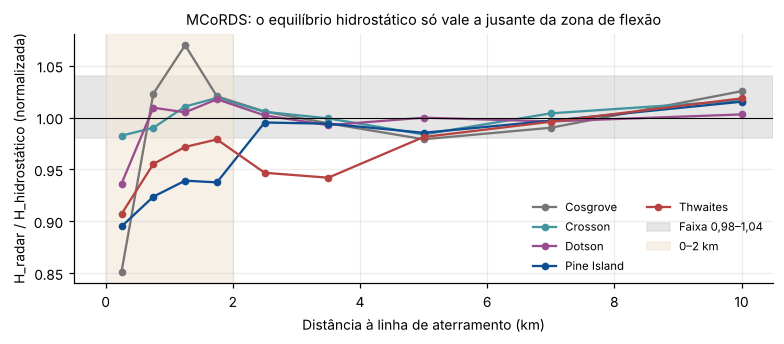

In [4]:
mcords = pd.read_csv(DATA_DIR / "mcords_razao_hidrostatica_por_distancia.csv")
lim = mcords["dist_gl_km"].str.extract(r"\(([\d.]+),\s*([\d.]+)\]").astype(float)
mcords["mid_km"] = lim.mean(axis=1)
mcords["zona"] = np.where(lim[1] <= 2.0, "0–2 km (zona de flexão)", "> 2 km (flutuação livre)")

fig, ax = plt.subplots(figsize=(7.2, 3.2))
for plat, g in mcords.groupby("plataforma"):
    cor = CORES.get(plat if plat != "Thwaites" else "Thwaites_TEIS", "#767676")
    ax.plot(g["mid_km"], g["razao_norm_med"], "o-", color=cor, ms=4, label=plat.replace("_", " "))
ax.axhspan(0.98, 1.04, color="#CFCECE", alpha=0.5, label="Faixa 0,98–1,04")
ax.axhline(1.0, color="k", lw=0.7); ax.axvspan(0, 2, color="#F2E6D8", alpha=0.6, label="0–2 km")
ax.set_xlabel("Distância à linha de aterramento (km)"); ax.set_ylabel("H_radar / H_hidrostático (normalizada)")
ax.set_title("MCoRDS: o equilíbrio hidrostático só vale a jusante da zona de flexão")
ax.legend(frameon=False, fontsize=7.5, ncol=2); plt.tight_layout()

resumo = (mcords.assign(peso=mcords["n"])
          .groupby(["plataforma", "zona"])
          .apply(lambda g: pd.Series({"Razão mediana ponderada": np.average(g["razao_norm_med"], weights=g["n"]),
                                      "Amostras radar": int(g["n"].sum()), "Voos (máx.)": int(g["voos"].max())}), include_groups=False)
          .unstack("zona"))
resumo.round(3)

**Leitura do resultado.**
- **A jusante de 2 km**, a razão fica entre ~0,94 e ~1,02 em todas as plataformas (médias ponderadas de 0,985–1,002): a espessura hidrostática do ICESat-2 concorda com o radar em poucos por cento, e o fator 9,34 com as densidades adotadas é adequado.
- **No primeiro meio quilômetro**, a razão cai para 0,85–0,94 em Cosgrove, Dotson, PIG e Thwaites. Na PIG o déficit persiste em todo o intervalo de 0–2 km (0,90–0,94): $H_{\text{hidro}}$ **superestima** a espessura real em 5–15%, porque parte do peso ainda é sustentada pela flexão. Aplicar $9{,}34\,h$ ali criaria um afinamento aparente quando o gelo é advectado através da faixa.
- Na Thwaites a recuperação é mais lenta: a razão só se aproxima de 1 depois de ~6 km, o que motivou a recuperação física da zona de aterramento da TEIS (correção de maré por $\beta_n$ e razão empírica radar/hidrostática), ampliando a cobertura em +48% sem o afinamento espúrio de ~7 m/ano.

---

---
## 3. Comparação com os 40 Sítios ApRES de Wild et al. (2024) no Centro da TEIS e Verificação de Folga da Cavidade Subglacial

No interior da plataforma oriental da Thwaites (TEIS), comparamos o produto de derretimento basal com os **40 registros ApRES publicados por Wild et al. (2024, *J. Glaciol.*, `validacao_apres_wild2024.csv`)** e verificamos no BedMachine v4.1 se células com resposta à maré $\beta$ reduzida a jusante de $d^*$ poderiam decorrer de aterramento raso ou contato com altos batimétricos (`open_check_6_beta_baixo_folga.csv`):

,n_beta_baixo,n_resto,folga_mediana_beta_baixo_m,folga_mediana_resto_m,frac_beta_baixo_folga_lt_50m,frac_resto_folga_lt_50m,crosson_2p5_3km_folga_mediana_m,crosson_2p5_3km_beta_mediano
plataforma,,,,,,,,
Cosgrove,134,1080,398.81,402.61,0.0,0.02,NaN,NaN
Crosson,6,96,591.26,461.11,0.0,0.00,417.77,0.75
Dotson,497,2842,679.03,751.11,0.0,0.00,NaN,NaN
Pine_Island,155,954,263.27,310.93,0.0,0.00,NaN,NaN
Thwaites,67,945,461.67,439.88,0.0,0.00,NaN,NaN


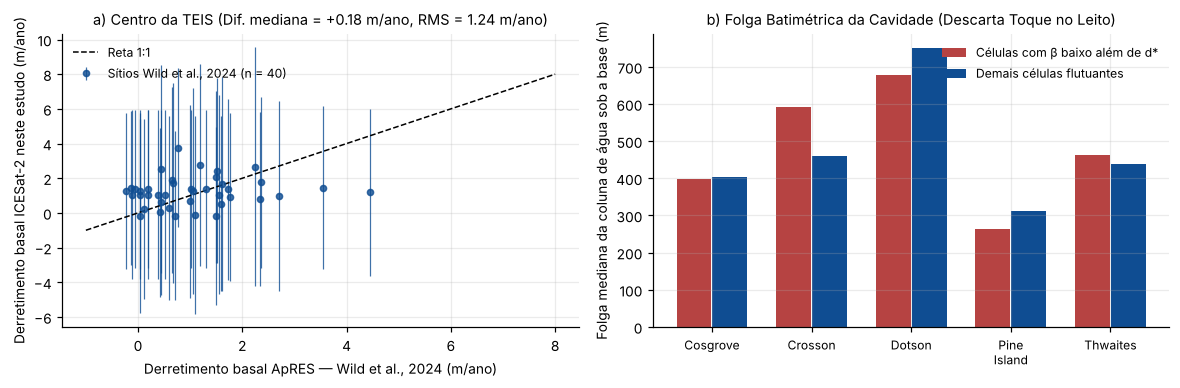

In [5]:
w_ok = wild_df.dropna(subset=["m_apres", "mb"]).copy()
diff_w = w_ok["mb"] - w_ok["m_apres"]

fig, ax = plt.subplots(1, 2, figsize=(10.8, 3.6))
ax[0].errorbar(w_ok["m_apres"], w_ok["mb"], yerr=w_ok["se"],
               fmt="o", color="#0F4D92", ms=4, alpha=0.8, elinewidth=0.8, label=f"Sítios Wild et al., 2024 (n = {len(w_ok)})")
ax[0].plot([-1, 8], [-1, 8], "k--", lw=1.0, label="Reta 1:1")
ax[0].set_xlabel("Derretimento basal ApRES — Wild et al., 2024 (m/ano)")
ax[0].set_ylabel("Derretimento basal ICESat-2 neste estudo (m/ano)")
ax[0].set_title(f"a) Centro da TEIS (Dif. mediana = {np.median(diff_w):+.2f} m/ano, RMS = {np.sqrt(np.mean(diff_w**2)):.2f} m/ano)")
ax[0].legend(frameon=False, fontsize=8)

x_f = np.arange(len(folga_df))
ax[1].bar(x_f - 0.18, folga_df["folga_mediana_beta_baixo_m"], width=0.35, color="#B64342", label="Células com β baixo além de d*")
ax[1].bar(x_f + 0.18, folga_df["folga_mediana_resto_m"], width=0.35, color="#0F4D92", label="Demais células flutuantes")
ax[1].set_xticks(x_f)
ax[1].set_xticklabels([p.replace("_", "\n") for p in folga_df["plataforma"]], fontsize=8)
ax[1].set_ylabel("Folga mediana da coluna de água sob a base (m)")
ax[1].set_title("b) Folga Batimétrica da Cavidade (Descarta Toque no Leito)")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

folga_df.set_index("plataforma").round(2)

In [6]:
w_ok = wild_df.dropna(subset=["m_apres", "mb"])
dif = w_ok["mb"] - w_ok["m_apres"]
sig_comb = np.hypot(w_ok["se"], w_ok["m_apres_err"])
pd.Series({
    "Sítios comparados": len(w_ok),
    "m_b médio ICESat-2 (m/ano)": w_ok["mb"].mean(),
    "m_b médio ApRES (m/ano)": w_ok["m_apres"].mean(),
    "Diferença mediana (m/ano)": dif.median(),
    "RMS da diferença (m/ano)": np.sqrt(np.mean(dif**2)),
    "Correlação de Pearson entre sítios": np.corrcoef(w_ok["mb"], w_ok["m_apres"])[0, 1],
    "σ mediano por pixel ICESat-2 (m/ano)": w_ok["se"].median(),
    "Desvio-padrão do ApRES entre sítios (m/ano)": w_ok["m_apres"].std(),
    "Fração com |dif| ≤ 2σ combinado": np.mean(np.abs(dif) <= 2 * sig_comb),
}).round(3).to_frame("Valor")

,Valor
Sítios comparados,40.000
m_b médio ICESat-2 (m/ano),1.216
m_b médio ApRES (m/ano),1.067
Diferença mediana (m/ano),0.177
RMS da diferença (m/ano),1.242
Correlação de Pearson entre sítios,0.137
σ mediano por pixel ICESat-2 (m/ano),4.998
Desvio-padrão do ApRES entre sítios (m/ano),1.032
Fração com |dif| ≤ 2σ combinado,1.000


**Leitura do resultado.**
- **Nível médio:** no centro da TEIS, o ICESat-2 e o ApRES concordam na média (≈ 1,1–1,2 m/ano; diferença mediana < 0,2 m/ano). Isso valida o produto na escala da plataforma.
- **Padrão entre sítios:** a correlação é baixa ($r \approx 0{,}14$). Não é discordância. A variação real entre os sítios ApRES (DP ~1 m/ano) é cinco vezes menor que o erro de um pixel ICESat-2 (~5 m/ano), então a altimetria não tem resolução para ordenar sítios separados por centenas de metros. Todos os 40 sítios concordam dentro de $2\sigma$.
- **Folga da cavidade (painel b):** células com $\beta$ reduzido a jusante de $d^*$ têm a mesma coluna de água sob a base (centenas de metros) que as demais, e nenhuma tem folga < 50 m. A resposta à maré reduzida não vem de toque no leito, e sim, provavelmente, de rigidez lateral ou da geometria da margem.

---
## 4. Síntese do Caderno

| Validação | Resultado | Implicação |
|---|---|---|
| Processamento ApRES (sintético) | deslocamentos e derretimento recuperados com erro sub-milimétrico | o módulo `apres` é confiável como referência |
| Sítios G1–G4 (ITGC) | 2–4 m/ano onde bem determinado | derretimento suprimido na zona de aterramento oriental |
| MCoRDS × hidrostático | razão ≈ 0,94–1,02 além de 2 km; 0,85–0,94 nos primeiros 500 m | hidrostática válida só a jusante de $d^*$; a zona de flexão exige recuperação física |
| 40 sítios Wild et al. (2024) | médias concordam (< 0,2 m/ano); padrão fino não resolvido | o produto vale na escala de plataforma, não de centenas de metros |
| Folga da cavidade | nenhuma célula com folga < 50 m | $\beta$ reduzido não indica aterramento |

**Scripts do pipeline:** `pipelines/derretimento_basal/run_mcords_hydro_test.py`, `run_gz_recovery_ase.py`, `run_thwaites_recovered.py`, `run_apres_validation.py`, `run_open_checks_ase.py`.

**Próximo caderno:** o Caderno 08 desce à sub-escala: canais basais, migração da linha de aterramento e fraturamento.